# CLIP product recognition
This notebook evaluates CLIP on ten original product images and fixed
image variations.


In [1]:
%pip install -q transformers pillow matplotlib pandas scikit-learn safetensors

In [ ]:
from pathlib import Path
import json
import hashlib
import shutil
import time
import platform

import numpy as np
import pandas as pd
import torch
import transformers
from PIL import Image, ImageOps, ImageEnhance, ImageFilter
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "Select a T4 GPU runtime first."

source = Path("/content/products_images")
project = Path("/content/product_recognition")

for folder in ["originals", "inputs", "results", "outputs", "evaluation"]:
    (project / folder).mkdir(parents=True, exist_ok=True)

products = {
    "Coca_Cola": "a bottle of Coca-Cola Classic",
    "Coffee_cup": "a black takeaway coffee cup with a white lid",
    "Doritos": "a red packet of Doritos Cheese Supreme corn chips",
    "KitKat": "a red wrapper of KitKat milk chocolate",
    "Mount_Franklin": "a bottle of Mount Franklin lightly sparkling water",
    "Oreo": "a blue and white packet of Oreo Double Stuf cookies",
    "Pringles": "a red cylindrical can of Pringles Original potato crisps",
    "Red_Bull": "a blue and silver can of Red Bull energy drink",
    "Red_Rock_Deli": (
        "a packet of Red Rock Deli sweet chilli and sour cream potato chips"
    ),
    "Smiths_Orginal": "a blue packet of Smith's Original potato chips",
}

extensions = {".jpg", ".jpeg", ".png", ".webp", ".avif"}
image_paths = {
    path.stem: path
    for path in source.iterdir()
    if path.is_file() and path.suffix.lower() in extensions
}

assert set(image_paths) == set(products), (
    f"Missing: {set(products) - set(image_paths)}; "
    f"Unexpected: {set(image_paths) - set(products)}"
)

records = []

for product, description in products.items():
    path = image_paths[product]

    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        width, height = image.size

    shutil.copy2(path, project / "originals" / path.name)

    records.append({
        "product": product,
        "description": description,
        "source_file": path.name,
        "width": width,
        "height": height,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    })

catalogue = pd.DataFrame(records)
catalogue.to_csv(project / "results/catalogue.csv", index=False)

with open(project / "results/candidate_labels.json", "w") as file:
    json.dump(products, file, indent=2)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Products:", len(catalogue))
display(catalogue[["product", "width", "height"]])

GPU: Tesla T4
PyTorch: 2.11.0+cu130
Transformers: 5.22.0
Products: 10


,product,width,height
0,Coca_Cola,1200,1200
1,Coffee_cup,480,480
2,Doritos,1200,1200
3,KitKat,1200,1200
4,Mount_Franklin,1200,1200
5,Oreo,1200,1200
6,Pringles,1200,1200
7,Red_Bull,1200,1200
8,Red_Rock_Deli,1200,1200
9,Smiths_Orginal,480,480


### Shared evaluation images
Each product has five fixed conditions such as original, darker, brighter,
blurred and centre crop.

The 50 images come from ten source photographs .

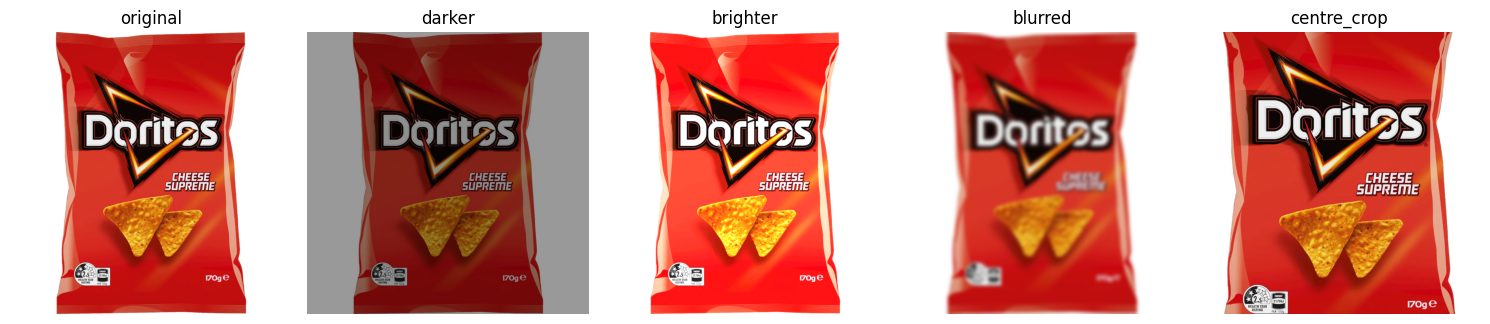

Prepared: 50 evaluation images
Source photographs: 10


In [3]:
conditions = {
    "original": {"operation": "unchanged"},
    "darker": {"brightness": 0.6},
    "brighter": {"brightness": 1.4},
    "blurred": {"gaussian_radius_fraction": 0.006},
    "centre_crop": {"retained_width_and_height": 0.8},
}

image_records = []

for product in products:
    with Image.open(image_paths[product]) as opened:
        original = ImageOps.exif_transpose(opened).convert("RGB")

    width, height = original.size

    cropped = original.crop((
        round(width * 0.1),
        round(height * 0.1),
        round(width * 0.9),
        round(height * 0.9),
    )).resize(original.size, Image.Resampling.LANCZOS)

    variants = {
        "original": original.copy(),
        "darker": ImageEnhance.Brightness(original).enhance(0.6),
        "brighter": ImageEnhance.Brightness(original).enhance(1.4),
        "blurred": original.filter(
            ImageFilter.GaussianBlur(
                radius=min(width, height) * 0.006
            )
        ),
        "centre_crop": cropped,
    }

    for condition, image in variants.items():
        relative_path = f"inputs/{product}_{condition}.png"
        output_path = project / relative_path
        image.save(output_path)

        image_records.append({
            "image_id": f"{product}_{condition}",
            "product": product,
            "condition": condition,
            "image_file": relative_path,
            "sha256": hashlib.sha256(
                output_path.read_bytes()
            ).hexdigest(),
        })

image_manifest = pd.DataFrame(image_records)
assert len(image_manifest) == 50
assert image_manifest["image_id"].is_unique

image_manifest.to_csv(
    project / "results/image_manifest.csv", index=False
)

with open(project / "results/image_conditions.json", "w") as file:
    json.dump(conditions, file, indent=2)

# Preview the conditions
example = image_manifest[
    image_manifest["product"] == "Doritos"
]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, row in zip(axes, example.itertuples()):
    with Image.open(project / row.image_file) as image:
        ax.imshow(image)
    ax.set_title(row.condition)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Prepared:", len(image_manifest), "evaluation images")
print("Source photographs:", image_manifest["product"].nunique())

In [ ]:
from huggingface_hub import model_info
from transformers import AutoProcessor, CLIPModel

device = torch.device("cuda")
model_id = "openai/clip-vit-base-patch32"

# Record the exact checkpoint revision
# revision = model_info(model_id).sha

# Pin the checkpoint revision recorded in the original CLIP experiment.
revision = "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"

start = time.perf_counter()

processor = AutoProcessor.from_pretrained(
    model_id, revision=revision
)

model = CLIPModel.from_pretrained(
    model_id,
    revision=revision,
    dtype=torch.float32,
).to(device)

model.eval()
torch.cuda.synchronize()
load_seconds = time.perf_counter() - start

run_config = {
    "model": "CLIP",
    "model_id": model_id,
    "revision": revision,
    "precision": "float32",
    "load_seconds": load_seconds,
    "parameters": sum(p.numel() for p in model.parameters()),
    "candidate_order": list(products),
    "candidate_descriptions": list(products.values()),
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "transformers": transformers.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "evaluation": "fixed ten-candidate zero-shot classification",
}

with open(project / "results/clip_config.json", "w") as file:
    json.dump(run_config, file, indent=2)

print("CLIP loaded.")
print("Revision:", revision)
print("Parameters:", run_config["parameters"])
print("Load seconds:", round(load_seconds, 2))

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP loaded.
Revision: 3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268
Parameters: 151277313
Load seconds: 7.95


### Predictions and measurements
Each image is ranked against the ten fixed product descriptions.
Top 1 and top 3 accuracy are recorded, together with all candidate scores.

Timing measures a forward pass for one image and ten descriptions.
Scores are ranking values.

In [5]:
candidate_ids = list(products)
candidate_texts = list(products.values())

prediction_records = []
score_records = []

# Warm up
first_path = project / image_manifest.iloc[0]["image_file"]

with Image.open(first_path) as opened:
    warmup_image = opened.convert("RGB")

warmup_inputs = processor(
    text=candidate_texts,
    images=warmup_image,
    return_tensors="pt",
    padding=True,
).to(device)

with torch.inference_mode():
    for _ in range(3):
        warmup_output = model(**warmup_inputs)

torch.cuda.synchronize()
del warmup_output, warmup_inputs

for row in image_manifest.itertuples(index=False):
    with Image.open(project / row.image_file) as opened:
        image = opened.convert("RGB")

    inputs = processor(
        text=candidate_texts,
        images=image,
        return_tensors="pt",
        padding=True,
    ).to(device)

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()

    with torch.inference_mode():
        output = model(**inputs)

    torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    peak_gib = torch.cuda.max_memory_allocated() / 1024**3

    scores = output.logits_per_image[0].float().cpu().numpy()
    assert np.isfinite(scores).all()

    ranking = np.argsort(-scores)
    ranked_ids = [candidate_ids[index] for index in ranking]
    true_rank = ranked_ids.index(row.product) + 1

    prediction_records.append({
        "model": "CLIP",
        "image_id": row.image_id,
        "product": row.product,
        "condition": row.condition,
        "image_file": row.image_file,
        "predicted_product": ranked_ids[0],
        "top3_products": " | ".join(ranked_ids[:3]),
        "true_product_rank": true_rank,
        "correct_top1": int(true_rank == 1),
        "correct_top3": int(true_rank <= 3),
        "top1_score": float(scores[ranking[0]]),
        "score_margin": float(
            scores[ranking[0]] - scores[ranking[1]]
        ),
        "forward_seconds": seconds,
        "peak_allocated_gpu_gib": peak_gib,
    })

    for rank, index in enumerate(ranking, start=1):
        score_records.append({
            "model": "CLIP",
            "image_id": row.image_id,
            "candidate": candidate_ids[index],
            "rank": rank,
            "score": float(scores[index]),
        })

    del output, inputs

predictions = pd.DataFrame(prediction_records)
candidate_scores = pd.DataFrame(score_records)

assert len(predictions) == 50
assert len(candidate_scores) == 500

predictions.to_csv(
    project / "outputs/clip_predictions.csv", index=False
)
candidate_scores.to_csv(
    project / "outputs/clip_candidate_scores.csv", index=False
)

condition_summary = predictions.groupby(
    "condition", sort=False
).agg(
    images=("image_id", "count"),
    top1_accuracy=("correct_top1", "mean"),
    top3_accuracy=("correct_top3", "mean"),
    mean_forward_seconds=("forward_seconds", "mean"),
)

condition_summary.to_csv(
    project / "results/clip_condition_summary.csv"
)

overall = pd.DataFrame([{
    "model": "CLIP",
    "images": len(predictions),
    "source_photographs": predictions["product"].nunique(),
    "top1_accuracy": predictions["correct_top1"].mean(),
    "top3_accuracy": predictions["correct_top3"].mean(),
    "mean_forward_seconds": predictions["forward_seconds"].mean(),
    "median_forward_seconds": predictions["forward_seconds"].median(),
    "peak_allocated_gpu_gib": (
        predictions["peak_allocated_gpu_gib"].max()
    ),
}])

overall.to_csv(
    project / "results/clip_overall_summary.csv", index=False
)

run_config["timing_scope"] = (
    "Warmed forward pass: one image and ten candidate texts; "
    "includes both encoders; excludes preprocessing, transfers, "
    "image loading and saving."
)

with open(project / "results/clip_config.json", "w") as file:
    json.dump(run_config, file, indent=2)

display(overall.round(4))
display(condition_summary.round(4))

errors = predictions[predictions["correct_top1"] == 0]
print("Top-1 errors:", len(errors))

display(errors[[
    "product", "condition", "predicted_product",
    "true_product_rank",
]])

print("Saved predictions, candidate rankings and summaries.")

,model,images,source_photographs,top1_accuracy,top3_accuracy,mean_forward_seconds,median_forward_seconds,peak_allocated_gpu_gib
0,CLIP,50,10,1.0,1.0,0.0224,0.0213,0.5799


,images,top1_accuracy,top3_accuracy,mean_forward_seconds
condition,,,,
original,10,1.0,1.0,0.0227
darker,10,1.0,1.0,0.0218
brighter,10,1.0,1.0,0.0224
blurred,10,1.0,1.0,0.0224
centre_crop,10,1.0,1.0,0.0226


Top-1 errors: 0


,product,condition,predicted_product,true_product_rank


Saved predictions, candidate rankings and summaries.


### CLIP findings
CLIP achieved 100% top-1 and top-3 accuracy across all five image
conditions. Mean forward time was 22.4 ms per image.

The test contains ten distinct products photographed against clean
backgrounds. Detailed candidate descriptions provide brand, colour
and packaging information. The perfect result limits the test's
ability to distinguish recognition quality between models.

In [6]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/pair4_clip_backup",
    "zip",
    root_dir=str(project),
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>